In [ ]:
# ==========================================
# Cell 1: Environment Setup & Authentication
# ==========================================
# نصب کتابخانه‌های مورد نیاز برای پردازش داده‌های مکانی
!pip install geopandas shapely db-dtypes pandas fiona osmnx -q

from google.colab import auth
# احراز هویت برای اتصال امن به Google Cloud
auth.authenticate_user()
print("✅ محیط با موفقیت آماده شد و احراز هویت انجام گردید.")

# تعریف متغیرهای ثابت پروژه
PROJECT_ID = 'siavak-temp-aliz'
DATASET_ID = 'divar_ml_data_prepration'

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 56.6/56.6 kB 2.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 17.2/17.2 MB 73.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 104.7/104.7 kB 6.0 MB/s eta 0:00:00
✅ محیط با موفقیت آماده شد و احراز هویت انجام گردید.


In [ ]:
# ==========================================
# Cell 2: Reference Data - Neighborhoods
# ==========================================
import pandas as pd
import json
import pandas_gbq

print("⏳ در حال پردازش فایل neighborhoods.json...")

with open('neighborhoods.json', 'r', encoding='utf-8') as f:
    data = json.load(f)

flat_data = []
for item in data:
    flat_data.append({
        'neighborhood_slug': item.get('slug'),
        'neighborhood_name': item.get('name'),
        'latitude': float(item.get('latitude')) if item.get('latitude') else None,
        'longitude': float(item.get('longitude')) if item.get('longitude') else None
    })

df_neighborhoods = pd.DataFrame(flat_data)
table_ref_neighborhoods_raw = f"{PROJECT_ID}.{DATASET_ID}.ref_neighborhoods_raw"

pandas_gbq.to_gbq(df_neighborhoods, destination_table=table_ref_neighborhoods_raw, project_id=PROJECT_ID, if_exists='replace')
print(f"✅ جدول مرجع محله‌ها (خام) در {table_ref_neighborhoods_raw} ذخیره شد.")

⏳ در حال پردازش فایل neighborhoods.json...


FileNotFoundError: [Errno 2] No such file or directory: 'neighborhoods.json'

In [ ]:
# ==========================================
# Cell 3: Reference Data - Metro Stations
# ==========================================
import pandas as pd
import json
import pandas_gbq

print("⏳ در حال پردازش فایل stations.json...")

with open('stations.json', 'r', encoding='utf-8') as f:
    stations_data = json.load(f)

flat_stations = []
for key, info in stations_data.items():
    flat_stations.append({
        'station_key': key,
        'station_name_fa': info.get('translations', {}).get('fa', key),
        'latitude': float(info.get('latitude')) if info.get('latitude') else None,
        'longitude': float(info.get('longitude')) if info.get('longitude') else None
    })

df_stations = pd.DataFrame(flat_stations).dropna(subset=['latitude', 'longitude'])
table_ref_metro = f"{PROJECT_ID}.{DATASET_ID}.ref_metro_stations"

pandas_gbq.to_gbq(df_stations, destination_table=table_ref_metro, project_id=PROJECT_ID, if_exists='replace')
print(f"✅ جدول مرجع ایستگاه‌های مترو در {table_ref_metro} ذخیره شد.")

In [ ]:
# ==========================================
# Cell 4: Reference Data - Commercial Points
# ==========================================
import geopandas as gpd
import pandas_gbq

print("⏳ در حال پردازش فایل tehran_commercial_points.geojson...")

gdf_commercial = gpd.read_file('tehran_commercial_points.geojson')

# استخراج مختصات از هندسه
gdf_commercial['longitude'] = gdf_commercial.geometry.x
gdf_commercial['latitude'] = gdf_commercial.geometry.y

df_commercial = pd.DataFrame(gdf_commercial.drop(columns=['geometry']))
table_ref_commercial = f"{PROJECT_ID}.{DATASET_ID}.ref_commercial_points"

pandas_gbq.to_gbq(df_commercial, destination_table=table_ref_commercial, project_id=PROJECT_ID, if_exists='replace')
print(f"✅ جدول مرجع نقاط تجاری در {table_ref_commercial} ذخیره شد.")

In [ ]:
# ==========================================
# Cell 5: Reference Data - Tehran Borders
# ==========================================
import geopandas as gpd
import pandas_gbq

print("⏳ در حال پردازش فایل 22-tehran.geojson...")

gdf_borders = gpd.read_file('22-tehran.geojson')

if 'Name' in gdf_borders.columns:
    gdf_borders = gdf_borders.rename(columns={'Name': 'district_name'})

# تبدیل چندضلعی‌ها به فرمت متنی WKT برای BigQuery
gdf_borders['geometry_wkt'] = gdf_borders.geometry.apply(lambda x: x.wkt)

df_borders = pd.DataFrame(gdf_borders.drop(columns=['geometry']))
table_ref_borders = f"{PROJECT_ID}.{DATASET_ID}.ref_tehran_borders"

pandas_gbq.to_gbq(df_borders, destination_table=table_ref_borders, project_id=PROJECT_ID, if_exists='replace')
print(f"✅ جدول مرجع مرزهای تهران در {table_ref_borders} ذخیره شد.")

In [ ]:
# ==========================================
# Cell 6: Spatial Filter - Clean Neighborhoods
# ==========================================
from google.cloud import bigquery

client = bigquery.Client(project=PROJECT_ID)

print("⏳ در حال تقاطع فضایی محله‌ها با مرزهای تهران...")

# استفاده از CAST برای جلوگیری از خطای String به Float
sql_clean_neighborhoods = f"""
CREATE OR REPLACE TABLE `{PROJECT_ID}.{DATASET_ID}.ref_neighborhoods` AS
SELECT DISTINCT n.*
FROM `{PROJECT_ID}.{DATASET_ID}.ref_neighborhoods_raw` n
CROSS JOIN `{PROJECT_ID}.{DATASET_ID}.ref_tehran_borders` b
WHERE ST_CONTAINS(
    ST_GEOGFROMTEXT(b.geometry_wkt),
    ST_GEOGPOINT(CAST(n.longitude AS FLOAT64), CAST(n.latitude AS FLOAT64))
);
"""

client.query(sql_clean_neighborhoods).result()
print(f"✅ محله‌های نامعتبر حذف شدند و جدول نهایی ref_neighborhoods ساخته شد.")

⏳ در حال تقاطع فضایی محله‌ها با مرزهای تهران...
✅ محله‌های نامعتبر حذف شدند و جدول نهایی ref_neighborhoods ساخته شد.


In [ ]:
# ==========================================
# Cell 7: Reference Data - Seismic Risk (Calibrated)
# ==========================================
import numpy as np
import pandas as pd
from PIL import Image
import pandas_gbq


print("⏳ در حال پردازش مجدد عکس زلزله با مختصات و رنگ‌های کالیبره‌شده...")

img = Image.open('tehran_seismic.jpg').convert('RGB')
img_arr = np.array(img)
height, width, _ = img_arr.shape

# مختصات کالیبره شده و دقیق‌تر بر اساس نقشه تهران
lon_min, lon_max = 51.100, 51.600
lat_min, lat_max = 35.530, 35.850

lons = np.arange(lon_min, lon_max, 0.002)
lats = np.arange(lat_min, lat_max, 0.002)

data_points = []

# منطق دقیق تشخیص رنگ شما برای ۴ سطح خطر
def get_risk_level(r, g, b):
    if (r > 200 and g > 200 and b > 200) or (r < 50 and g < 50 and b < 50): return None
    if r > 150 and g < 100 and b < 100: return 4 # قرمز (Very High)
    if r > 200 and g > 100 and g < 180 and b < 100: return 3 # نارنجی (High)
    if r > 180 and g > 180 and b < 150: return 2 # زرد (Moderate)
    if r < 150 and g > 150 and b < 150: return 1 # سبز (Low)
    return None

for lon in lons:
    for lat in lats:
        px_x = int((lon - lon_min) / (lon_max - lon_min) * (width - 1))
        px_y = int((lat_max - lat) / (lat_max - lat_min) * (height - 1))

        if 0 <= px_x < width and 0 <= px_y < height:
            r, g, b = img_arr[px_y, px_x]
            risk = get_risk_level(r, g, b)
            if risk is not None:
                data_points.append({'longitude': lon, 'latitude': lat, 'seismic_risk_level': risk})

df_seismic = pd.DataFrame(data_points)

table_ref_seismic = f"{PROJECT_ID}.{DATASET_ID}.ref_seismic_risk"

pandas_gbq.to_gbq(df_seismic, destination_table=table_ref_seismic, project_id=PROJECT_ID, if_exists='replace')
print(f"🎉 جدول زلزله با مختصات و ریسک‌های جدید در {table_ref_seismic} آپدیت شد.")

⏳ در حال پردازش مجدد عکس زلزله با مختصات و رنگ‌های کالیبره‌شده...


100%|██████████| 1/1 [00:00<00:00, 8224.13it/s]

🎉 جدول زلزله با مختصات و ریسک‌های جدید در siavak-temp-aliz.divar_ml_data_prepration.ref_seismic_risk آپدیت شد.


In [ ]:
# ==========================================
# Cell 8: Reference Data - Traffic Zones
# ==========================================

import fiona
import geopandas as gpd
import pandas as pd
import pandas_gbq

print("⏳ در حال پردازش KML طرح ترافیک...")
fiona.drvsupport.supported_drivers['KML'] = 'rw'
gdf_traffic = gpd.read_file('محدوده طرح ترافیک تهران.kml', driver='KML')

# منطق اصلی شما برگردانده شد
def assign_traffic_status(name):
    if 'آلودگی' in str(name): return 1
    elif 'ترافیک' in str(name): return 2
    return 0

gdf_traffic['traffic_zone_status'] = gdf_traffic['Name'].apply(assign_traffic_status)
gdf_traffic['geometry_wkt'] = gdf_traffic.geometry.apply(lambda x: x.wkt if x else None)

df_final_traffic = pd.DataFrame(gdf_traffic[['Name', 'traffic_zone_status', 'geometry_wkt']])
df_final_traffic.rename(columns={'Name': 'zone_name'}, inplace=True) # تغییر نام ستون مطابق چک‌نویس

pandas_gbq.to_gbq(df_final_traffic, f"{PROJECT_ID}.{DATASET_ID}.ref_traffic_zones", project_id=PROJECT_ID, if_exists='replace')

⏳ در حال پردازش KML طرح ترافیک...


100%|██████████| 1/1 [00:00<00:00, 8648.05it/s]


In [ ]:
# ==========================================
# Cell 9: Reference Data - Air Quality (AQI)
# ==========================================
import numpy as np
import pandas as pd
from scipy.spatial import distance_matrix
import pandas_gbq

print("⏳ در حال تولید نقشه کیفیت هوا با الگوریتم IDW...")

stations_data = [
    {'name': 'اقدسیه', 'lat': 35.795, 'lon': 51.488, 'aqi': 75},
    {'name': 'پونک', 'lat': 35.761, 'lon': 51.336, 'aqi': 82},
    {'name': 'شهرری', 'lat': 35.589, 'lon': 51.432, 'aqi': 120},
    {'name': 'شادآباد', 'lat': 35.666, 'lon': 51.288, 'aqi': 115},
    {'name': 'مرکز شهر', 'lat': 35.700, 'lon': 51.400, 'aqi': 130}
]
df_stations_aqi = pd.DataFrame(stations_data)

grid_lons = np.linspace(51.100, 51.600, 100)
grid_lats = np.linspace(35.530, 35.850, 100)
grid_lon, grid_lat = np.meshgrid(grid_lons, grid_lats)

grid_points = np.column_stack((grid_lat.ravel(), grid_lon.ravel()))
station_points = df_stations_aqi[['lat', 'lon']].values
aqi_values = df_stations_aqi['aqi'].values

# محاسبه فاصله و وزن‌دهی
dist = distance_matrix(grid_points, station_points)
dist[dist == 0] = 1e-10
weights = 1.0 / (dist ** 2)
grid_aqi = np.sum(weights * aqi_values, axis=1) / np.sum(weights, axis=1)

df_grid_aqi = pd.DataFrame({'latitude': grid_points[:, 0], 'longitude': grid_points[:, 1], 'long_term_aqi': grid_aqi})
table_ref_aqi = f"{PROJECT_ID}.{DATASET_ID}.ref_air_quality"

pandas_gbq.to_gbq(df_grid_aqi, destination_table=table_ref_aqi, project_id=PROJECT_ID, if_exists='replace')
print(f"✅ جدول مرجع کیفیت هوا در {table_ref_aqi} ذخیره شد.")

⏳ در حال تولید نقشه کیفیت هوا با الگوریتم IDW...


100%|██████████| 1/1 [00:00<00:00, 8456.26it/s]

✅ جدول مرجع کیفیت هوا در siavak-temp-aliz.divar_ml_data_prepration.ref_air_quality ذخیره شد.


In [ ]:
# ==========================================
# Cell 10: Reference Data - Urban Decay
# ==========================================
import geopandas as gpd
import pandas as pd
import fiona
import zipfile
import os
import pandas_gbq

print("⏳ در حال استخراج و پردازش بافت فرسوده...")

fiona.drvsupport.supported_drivers['KML'] = 'rw'
fiona.drvsupport.supported_drivers['libKML'] = 'rw'

kmz_file = 'Baft Farsudeh Teh_LayerToKML.kmz'
kml_extracted = 'urban_decay_extracted.kml'

if os.path.exists(kmz_file):
    with zipfile.ZipFile(kmz_file, 'r') as kmz:
        kml_filename = [f for f in kmz.namelist() if f.endswith('.kml')][0]
        kmz.extract(kml_filename)
        os.rename(kml_filename, kml_extracted)

    gdf_decay = gpd.read_file(kml_extracted, driver='KML')
    gdf_decay['decay_zone_name'] = gdf_decay['Name']
    gdf_decay['geometry_wkt'] = gdf_decay.geometry.apply(lambda x: x.wkt if x else None)

    df_decay = pd.DataFrame(gdf_decay.drop(columns=['geometry']))
    table_ref_decay = f"{PROJECT_ID}.{DATASET_ID}.ref_urban_decay"

    pandas_gbq.to_gbq(df_decay, destination_table=table_ref_decay, project_id=PROJECT_ID, if_exists='replace')
    print(f"✅ جدول مرجع بافت فرسوده در {table_ref_decay} ذخیره شد.")
else:
    print("⚠️ فایل KMZ یافت نشد. در صورت اجرای قبلی، نیازی به این مرحله نیست.")

⏳ در حال استخراج و پردازش بافت فرسوده...
⚠️ فایل KMZ یافت نشد. در صورت اجرای قبلی، نیازی به این مرحله نیست.


In [ ]:
# ==========================================
# Cell 11: Reference Data - Highways (OSM)
# ==========================================
import osmnx as ox
import pandas as pd
import pandas_gbq

print("⏳ در حال دانلود گراف بزرگراه‌ها از OpenStreetMap...")

place_name = "Tehran, Iran"
custom_filter = '["highway"~"motorway|trunk|primary"]'

G = ox.graph_from_place(place_name, network_type='drive', custom_filter=custom_filter)
gdf_edges = ox.graph_to_gdfs(G, nodes=False, edges=True)

gdf_edges['geometry_wkt'] = gdf_edges.geometry.apply(lambda x: x.wkt)
df_highways = pd.DataFrame(gdf_edges[['name', 'highway', 'geometry_wkt']])
df_highways['name'] = df_highways['name'].apply(lambda x: str(x) if isinstance(x, list) else x)

table_ref_highways = f"{PROJECT_ID}.{DATASET_ID}.ref_highways"
pandas_gbq.to_gbq(df_highways, destination_table=table_ref_highways, project_id=PROJECT_ID, if_exists='replace')
print(f"✅ جدول مرجع بزرگراه‌ها در {table_ref_highways} ذخیره شد.")

⏳ در حال دانلود گراف بزرگراه‌ها از OpenStreetMap...


KeyboardInterrupt: 

In [ ]:
# ==========================================
# Cell 11.5: Remove Suburbs & Nullify Bad GPS
# ==========================================
from google.cloud import bigquery


client = bigquery.Client(project=PROJECT_ID)

table_inaccurate = f"{PROJECT_ID}.{DATASET_ID}.stg_tehran_residential_missing_locations"
table_borders = f"{PROJECT_ID}.{DATASET_ID}.ref_tehran_borders"

print("⏳ در حال پاکسازی داده‌های خارج از مرز تهران...")

# ۱. حذف کامل آگهی‌های حاشیه‌ای (خارج از ۲۲ منطقه) از کل دیتاست
sql_delete_suburbs = f"""
DELETE FROM `{table_inaccurate}`
WHERE neighborhood_slug IN (
    'sharifabad', 'qiamdash', 'saeed-abad', 'karim-abad',
    'hasan-abad-baqer-far', 'sorkhe-hesar', 'mesgar-abad', 'hezarsang', 'qasr-e-firooze-do'
);
"""
job_delete = client.query(sql_delete_suburbs)
job_delete.result()
print(f"✅ عالی! تعداد {job_delete.num_dml_affected_rows} آگهی حاشیه‌ای کلاً از دیتابیس حذف شدند.")

# ۲. پاک کردن (NULL) لوکیشنِ آگهی‌های داخل تهران که پین نقشه آن‌ها اشتباهی خارج از شهر افتاده
sql_nullify_bad_gps = f"""
UPDATE `{table_inaccurate}`
SET location_latitude = NULL, location_longitude = NULL
WHERE location_latitude IS NOT NULL
  AND location_longitude IS NOT NULL
  AND ST_DISTANCE(
    ST_GEOGPOINT(CAST(location_longitude AS FLOAT64), CAST(location_latitude AS FLOAT64)),
    (SELECT ST_UNION_AGG(ST_GEOGFROMTEXT(geometry_wkt)) FROM `{table_borders}`)
  ) > 500;
"""
job_update = client.query(sql_nullify_bad_gps)
job_update.result()
print(f"✅ تعداد {job_update.num_dml_affected_rows} آگهی معتبر با GPS غلط شناسایی و لوکیشن آن‌ها برای ترمیم، NULL شد.")

⏳ در حال پاکسازی داده‌های خارج از مرز تهران...
✅ عالی! تعداد 1 آگهی حاشیه‌ای کلاً از دیتابیس حذف شدند.
✅ تعداد 0 آگهی معتبر با GPS غلط شناسایی و لوکیشن آن‌ها برای ترمیم، NULL شد.


In [ ]:
# ==========================================
# Cell 12: Smart Spatial Imputation (Corrected)
# ==========================================
import pandas as pd
from google.cloud import bigquery
import numpy as np
import pandas_gbq

PROJECT_ID = 'siavak-temp-aliz'
DATASET_ID = 'divar_ml_data_prepration'
client = bigquery.Client(project=PROJECT_ID)
# مپینگ حیاتی نام محله‌ها
slug_mapping = {
    'ostad-moein': 'dr-hoshyar', 'narmak': 'sarsabz', 'mirdamad': 'zafar',
    'shahrak-e-gharb': 'eivanak', 'ozgol': 'araj', 'estakhr': 'khak-sefid',
    'elm-o-sanat': 'oghaf', 'shahrak-shahid-bagheri': 'abshar-tehran',
    'eslam-abad': 'shahrak-e-vali-e-asr', 'esfandyari': 'khani-abad-no',
    'north-shahran': 'north-shahran', 'khalij-e-fars': 'khalij-e-fars',
    'shaharak-e-shariyati': 'shaharak-e-shariyati', 'shahrak-naft-district5': 'shahrak-naft-district5',
    'mobarak-abad-e-beheshti': 'mobarak-abad-e-beheshti', 'sizdah-aban': 'sizdah-aban',
    'sharifabad': 'sharifabad', 'shahrak-e-taleghani': 'shahrak-e-taleghani',
    'qiamdash': 'qiamdash', 'shaharak-e-moslemin': 'shaharak-e-moslemin',
    'shahrak-e-aboozar': 'shahrak-e-aboozar', 'safaiye': 'safaiye',
    'saeed-abad': 'saeed-abad', 'karim-abad': 'karim-abad', 'hezarsang': 'hezarsang',
    'sorkhe-hesar': 'sorkhe-hesar', 'hasan-abad-baqer-far': 'hasan-abad-baqer-far',
    'shaharak-e-sharifi': 'shaharak-e-sharifi', 'abdollah-abad': 'abdollah-abad',
    'qasr-e-firoozeh-yek': 'qasr-e-firoozeh-yek', 'mesgar-abad': 'mesgar-abad',
    'east-saleh-abad': 'east-saleh-abad', 'qasr-e-firooze-do': 'qasr-e-firooze-do'
}

# دیکشنری ۲۱ محله
fallback_coords = {
    'abdollah-abad': {'lat': 35.568, 'lon': 51.428}, 'east-saleh-abad': {'lat': 35.610, 'lon': 51.390},
    'hasan-abad-baqer-far': {'lat': 35.539, 'lon': 51.405}, 'hezarsang': {'lat': 35.753, 'lon': 51.758},
    'karim-abad': {'lat': 35.520, 'lon': 51.465}, 'khalij-e-fars': {'lat': 35.688, 'lon': 51.311},
    'mesgar-abad': {'lat': 35.630, 'lon': 51.520}, 'mobarak-abad-e-beheshti': {'lat': 35.753, 'lon': 51.488},
    'north-shahran': {'lat': 35.768, 'lon': 51.282}, 'qasr-e-firoozeh-yek': {'lat': 35.670, 'lon': 51.500},
    'qiamdash': {'lat': 35.541, 'lon': 51.584}, 'saeed-abad': {'lat': 35.590, 'lon': 51.150},
    'safaiye': {'lat': 35.589, 'lon': 51.450}, 'shaharak-e-moslemin': {'lat': 35.660, 'lon': 51.310},
    'shaharak-e-shariyati': {'lat': 35.628, 'lon': 51.378}, 'shahrak-e-aboozar': {'lat': 35.655, 'lon': 51.470},
    'shahrak-e-taleghani': {'lat': 35.753, 'lon': 51.411}, 'shahrak-naft-district5': {'lat': 35.783, 'lon': 51.311},
    'sharifabad': {'lat': 35.428, 'lon': 51.786}, 'sizdah-aban': {'lat': 35.597, 'lon': 51.403},
    'sorkhe-hesar': {'lat': 35.708, 'lon': 51.564}
}

print("⏳ در حال خواندن داده‌های خام از BigQuery...")
df = client.query(f"SELECT * FROM `{PROJECT_ID}.{DATASET_ID}.stg_tehran_residential_missing_locations`").to_dataframe()
df_nodes = client.query(f"SELECT neighborhood_slug, latitude, longitude FROM `{PROJECT_ID}.{DATASET_ID}.ref_neighborhoods`").to_dataframe()

# ذخیره ماسک اولیه برای ساخت ستون is_imputed در انتها
mask_originally_null = df['location_latitude'].isna()

# 🛠 گام صفر: حتماً نام‌ها را قبل از هرکاری مپ می‌کنیم
df['neighborhood_slug'] = df['neighborhood_slug'].replace(slug_mapping)

print("🧠 در حال محاسبه مراکز ثقل و تراکم آگهی‌ها...")
# محاسبه میانگین و تعداد آگهی‌های سالم برای هر محله
valid_locations = df.dropna(subset=['location_latitude', 'location_longitude'])
agg_df = valid_locations.groupby('neighborhood_slug').agg(
    calc_lat=('location_latitude', 'mean'),
    calc_lon=('location_longitude', 'mean'),
    valid_count=('location_latitude', 'count')
).reset_index()

# متصل کردن اطلاعات میانگین‌ها و اطلاعات فایل JSON به دیتافریم اصلی
df = df.merge(agg_df, on='neighborhood_slug', how='left')
df = df.merge(df_nodes, on='neighborhood_slug', how='left')

# ======================================================================
# اجرای دقیق منطق ۴ مرحله‌ای شما (اولویت‌بندی)
# ======================================================================

# مرحله ۱: اگر بالای ۱۰۰ آگهی داشت -> از میانگین آگهی‌ها پر کن
cond1 = df['location_latitude'].isna() & (df['valid_count'] > 100)
df.loc[cond1, 'location_latitude'] = df.loc[cond1, 'calc_lat']
df.loc[cond1, 'location_longitude'] = df.loc[cond1, 'calc_lon']

# مرحله ۲: اگر هنوز Null بود و در فایل JSON مختصات داشت (مثل gandi) -> از فایل JSON پر کن
cond2 = df['location_latitude'].isna() & df['latitude'].notna()
df.loc[cond2, 'location_latitude'] = df.loc[cond2, 'latitude']
df.loc[cond2, 'location_longitude'] = df.loc[cond2, 'longitude']

# مرحله ۳: اگر هنوز Null بود -> از دیکشنری دستی fallback استفاده کن
def apply_fallback(row):
    slug = row['neighborhood_slug']
    if pd.isna(row['location_latitude']) and slug in fallback_coords:
        row['location_latitude'] = fallback_coords[slug]['lat']
        row['location_longitude'] = fallback_coords[slug]['lon']
    return row
df = df.apply(apply_fallback, axis=1)

# مرحله ۴: اگر باز هم Null بود -> میانگین همون محل رو بگیر هر تعداد بود
cond4 = df['location_latitude'].isna() & df['calc_lat'].notna()
df.loc[cond4, 'location_latitude'] = df.loc[cond4, 'calc_lat']
df.loc[cond4, 'location_longitude'] = df.loc[cond4, 'calc_lon']

# ======================================================================

# ثبت لیبل Impute
df['is_imputed'] = 0
df.loc[mask_originally_null, 'is_imputed'] = 1

# تمیزکاری ستون‌های موقت
df_final = df.drop(columns=['latitude', 'longitude', 'calc_lat', 'calc_lon', 'valid_count'])

# گزارش نهایی
final_null_count = df_final['location_latitude'].isna().sum()
imputed_count = mask_originally_null.sum()

print(f"✅ جایگذاری با دقت انجام شد: تعداد {imputed_count} رکورد ترمیم شدند.")
print(f"📊 وضعیت لوکیشن‌های خالی در حال حاضر (باید صفر باشد): {final_null_count} رکورد.")

# ذخیره در جدول نهایی مرحله ۲
table_output = f"{PROJECT_ID}.{DATASET_ID}.stg_residential_imputed"
print(f"⏳ در حال ذخیره جدول در {table_output}...")
pandas_gbq.to_gbq(df_final, destination_table=table_output, project_id=PROJECT_ID, if_exists='replace')
print("🎉 تمام شد! جدول نهایی آماده انجام محاسبات مکانی است.")

⏳ در حال خواندن داده‌های خام از BigQuery...
🧠 در حال محاسبه مراکز ثقل و تراکم آگهی‌ها...
✅ جایگذاری با دقت انجام شد: تعداد 37558 رکورد ترمیم شدند.
📊 وضعیت لوکیشن‌های خالی در حال حاضر (باید صفر باشد): 0 رکورد.
⏳ در حال ذخیره جدول در siavak-temp-aliz.divar_ml_data_prepration.stg_residential_imputed...


100%|██████████| 1/1 [00:00<00:00, 7371.36it/s]

🎉 تمام شد! جدول نهایی آماده انجام محاسبات مکانی است.


In [ ]:
# ==========================================
# Cell 13: Feature Engineering Master Pipeline
# ==========================================
from google.cloud import bigquery
import warnings
warnings.filterwarnings('ignore')

PROJECT_ID = 'siavak-temp-aliz'
DATASET_ID = 'divar_ml_data_prepration'
client = bigquery.Client(project=PROJECT_ID)

table_input = f"{PROJECT_ID}.{DATASET_ID}.stg_residential_imputed"
table_output = f"{PROJECT_ID}.{DATASET_ID}.ml_ready_tehran_residential_features_added"

print("⏳ در حال ساخت ویژگی‌های مکانی و اقتصادی در BigQuery...")

# استفاده از ساختار f-string معمولی با اصلاح دقیق کاراکترهای اسکیپ Regex
sql_master_pipeline = f"""
CREATE OR REPLACE TABLE `{table_output}` AS
WITH
  base_data AS (
    SELECT
      CAST(FARM_FINGERPRINT(TO_JSON_STRING(t)) AS STRING) as _uid,
      ST_GEOGPOINT(CAST(location_longitude AS FLOAT64), CAST(location_latitude AS FLOAT64)) as geom,
      IFNULL(CAST(has_elevator AS BOOL), FALSE) AS has_elevator,
      IFNULL(CAST(has_parking AS BOOL), FALSE) AS has_parking,
      IFNULL(CAST(has_warehouse AS BOOL), FALSE) AS has_warehouse,
      IFNULL(CAST(is_rebuilt AS BOOL), FALSE) AS is_rebuilt,
      IFNULL(is_imputed, 0) AS is_centroid_imputed,
      IF(cat2_slug LIKE '%rent%', 1, 0) AS is_price_converted,
      IF(cat3_slug LIKE '%house-villa%', 1, 0) AS is_villa,
      IFNULL(SAFE_CAST(REGEXP_EXTRACT(floor, r'[0-9]+') AS INT64), 0) AS floor_num,
      ROUND(CAST(Price_per_Sqm_MT AS FLOAT64), 2) AS price_per_sqm_mt,
      t.* EXCEPT(
          has_elevator, has_parking, has_warehouse, is_rebuilt,
          cat2_slug, cat3_slug, is_imputed,
          unified_estimated_price, Price_per_Sqm, Price_per_Sqm_MT
      )
    FROM `{table_input}` AS t
  ),

  comm_geom AS (SELECT ST_GEOGPOINT(CAST(longitude AS FLOAT64), CAST(latitude AS FLOAT64)) as geom FROM `{PROJECT_ID}.{DATASET_ID}.ref_commercial_points`),
  metro_geom AS (SELECT ST_GEOGPOINT(CAST(longitude AS FLOAT64), CAST(latitude AS FLOAT64)) as geom FROM `{PROJECT_ID}.{DATASET_ID}.ref_metro_stations`),
  aqi_geom AS (SELECT ST_GEOGPOINT(CAST(longitude AS FLOAT64), CAST(latitude AS FLOAT64)) as geom, CAST(long_term_aqi AS FLOAT64) as aqi FROM `{PROJECT_ID}.{DATASET_ID}.ref_air_quality`),
  seismic_geom AS (SELECT ST_GEOGPOINT(CAST(longitude AS FLOAT64), CAST(latitude AS FLOAT64)) as geom, CAST(seismic_risk_level AS INT64) as seismic_risk_level FROM `{PROJECT_ID}.{DATASET_ID}.ref_seismic_risk`),

  -- اصلاح دقیق رگولار اکسپرشن (جلوگیری از باگ اسکیپ در پایتون)
  decay_geom AS (
    SELECT
      ST_GEOGFROMTEXT(REGEXP_REPLACE(REPLACE(REPLACE(geometry_wkt, ' Z', ''), ' ZM', ''), r'([0-9eE.-]+\\s+[0-9eE.-]+)\\s+[0-9eE.-]+(?:\\s+[0-9eE.-]+)?', r'\\1')) as geom,
      CASE
        WHEN decay_zone_name = 'فرسوده' THEN 4
        WHEN decay_zone_name LIKE '%-%' THEN 3
        WHEN decay_zone_name IN ('ریزدانگی', 'ناپایداری', 'نفوذناپذیری') THEN 2
        WHEN decay_zone_name = 'سایر' THEN 1 ELSE 0
      END as decay_class
    FROM `{PROJECT_ID}.{DATASET_ID}.ref_urban_decay`
  ),

  hwy_geom AS (
    SELECT ST_GEOGFROMTEXT(REGEXP_REPLACE(REPLACE(REPLACE(geometry_wkt, ' Z', ''), ' ZM', ''), r'([0-9eE.-]+\\s+[0-9eE.-]+)\\s+[0-9eE.-]+(?:\\s+[0-9eE.-]+)?', r'\\1')) as geom
    FROM `{PROJECT_ID}.{DATASET_ID}.ref_highways`
  ),

  traffic_geom AS (
    SELECT
      ST_GEOGFROMTEXT(REGEXP_REPLACE(REPLACE(REPLACE(geometry_wkt, ' Z', ''), ' ZM', ''), r'([0-9eE.-]+\\s+[0-9eE.-]+)\\s+[0-9eE.-]+(?:\\s+[0-9eE.-]+)?', r'\\1')) as geom,
      CAST(traffic_zone_status AS INT64) AS traffic_score
    FROM `{PROJECT_ID}.{DATASET_ID}.ref_traffic_zones`
  ),

  comm_calc AS (SELECT b._uid, COUNT(c.geom) as comm_density FROM base_data b INNER JOIN comm_geom c ON ST_DWITHIN(b.geom, c.geom, 500) GROUP BY b._uid),
  metro_calc AS (SELECT b._uid, MIN(ST_DISTANCE(b.geom, m.geom)) as dist_metro FROM base_data b INNER JOIN metro_geom m ON ST_DWITHIN(b.geom, m.geom, 10000) GROUP BY b._uid),
  hwy_calc AS (SELECT b._uid, MIN(ST_DISTANCE(b.geom, h.geom)) as dist_hwy FROM base_data b INNER JOIN hwy_geom h ON ST_DWITHIN(b.geom, h.geom, 5000) GROUP BY b._uid),
  decay_calc AS (SELECT b._uid, MAX(u.decay_class) as decay_class FROM base_data b INNER JOIN decay_geom u ON ST_INTERSECTS(b.geom, u.geom) GROUP BY b._uid),
  traffic_calc AS (SELECT b._uid, MAX(t.traffic_score) as traffic_score FROM base_data b INNER JOIN traffic_geom t ON ST_INTERSECTS(b.geom, t.geom) GROUP BY b._uid),
  seismic_calc AS (SELECT b._uid, ROUND(AVG(s.seismic_risk_level)) as seismic_risk FROM base_data b INNER JOIN seismic_geom s ON ST_DWITHIN(b.geom, s.geom, 500) GROUP BY b._uid),
  aqi_calc AS (
    SELECT b._uid, (ARRAY_AGG(a.aqi ORDER BY ST_DISTANCE(b.geom, a.geom) ASC LIMIT 1))[OFFSET(0)] AS local_aqi
    FROM base_data b INNER JOIN aqi_geom a ON ST_DWITHIN(b.geom, a.geom, 20000) GROUP BY b._uid
  )

SELECT
    b.title,
    b.* EXCEPT(_uid, geom, floor_num, title),
    ROUND(COALESCE(c.comm_density, 0)) AS commercial_density,
    ROUND(COALESCE(m.dist_metro, 10000)) AS dist_to_metro,
    ROUND(ST_DISTANCE(b.geom, ST_GEOGPOINT(51.4183, 35.6961))) AS dist_to_cbd,
    ROUND(COALESCE(h.dist_hwy, 5000)) AS dist_to_highway,
    CAST(COALESCE(sk.seismic_risk, 1) AS INT64) AS seismic_risk_level,
    ROUND(COALESCE(aq.local_aqi, 0), 1) AS air_quality_aqi,
    COALESCE(tr.traffic_score, 0) AS traffic_zone_status,
    COALESCE(u.decay_class, 0) AS urban_decay_class,
    IF(b.floor_num > 2 AND b.has_elevator = FALSE, 1, 0) AS floor_elevator_penalty,
    IF(b.building_age > 20 AND b.is_rebuilt = TRUE, 1, 0) AS value_retention_bonus,
    ROUND(COALESCE(c.comm_density, 0) * (1.0 / (COALESCE(m.dist_metro, 10000) + 1)), 4) AS bonus_tod_livability,
    COALESCE(c.comm_density, 0) * COALESCE(u.decay_class, 0) AS penalty_traffic_nuisance,
    ROUND(ST_DISTANCE(b.geom, ST_GEOGPOINT(51.4183, 35.6961)) * (1.0 / (COALESCE(m.dist_metro, 10000) + 1)), 4) AS suburban_metro_dependency,
    IF(COALESCE(u.decay_class, 0) >= 3 AND b.building_age > 25, 1, 0) AS redevelopment_premium,
    IF(COALESCE(h.dist_hwy, 10000) > 200 AND COALESCE(h.dist_hwy, 10000) < 800, 1, 0) AS highway_sweetspot

FROM base_data b
LEFT JOIN comm_calc c ON b._uid = c._uid
LEFT JOIN metro_calc m ON b._uid = m._uid
LEFT JOIN hwy_calc h ON b._uid = h._uid
LEFT JOIN decay_calc u ON b._uid = u._uid
LEFT JOIN traffic_calc tr ON b._uid = tr._uid
LEFT JOIN aqi_calc aq ON b._uid = aq._uid
LEFT JOIN seismic_calc sk ON b._uid = sk._uid;
"""

job_config = bigquery.QueryJobConfig()
query_job = client.query(sql_master_pipeline, job_config=job_config)
query_job.result()

print("✅ غول مرحله آخر با موفقیت اجرا شد! دیتاست نهایی روی BigQuery ثبت گردید.")

⏳ در حال ساخت ویژگی‌های مکانی و اقتصادی در BigQuery...
✅ غول مرحله آخر با موفقیت اجرا شد! دیتاست نهایی روی BigQuery ثبت گردید.


In [ ]:
# ==========================================
# Cell 14: Schema Documentation
# ==========================================
from google.cloud import bigquery

client = bigquery.Client(project=PROJECT_ID)
table_output = f"{PROJECT_ID}.{DATASET_ID}.ml_ready_tehran_residential_features_added"

column_descriptions = {
    "title": "عنوان آگهی مسکن",
    "is_centroid_imputed": "کنترل خطای مکانی: اگر مختصات آگهی به مرکز محله مپ شده باشد مقدار ۱ می‌گیرد.",
    "is_price_converted": "کنترل نویز مالی: اگر قیمت کل، حاصل تبدیل رهن و اجاره باشد مقدار ۱ می‌گیرد.",
    "is_villa": "کنترل کالبدی: ۱ = خانه ویلایی/دربستی، ۰ = آپارتمان.",
    "price_per_sqm_mt": "قیمت هر متر مربع (میلیون تومان) - گرد شده تا ۲ رقم اعشار",
    "commercial_density": "مطلوبیت محلی: چگالی تراکم تجاری در شعاع ۵۰۰ متری (تعداد مراکز).",
    "dist_to_metro": "دسترسی‌پذیری: فاصله هندسی تا نزدیک‌ترین ایستگاه مترو (به متر).",
    "dist_to_cbd": "مدل شهر تک‌مرکزی: فاصله مستقیم تا مرکز ثقل اشتغال شهر (میدان فردوسی/بازار).",
    "dist_to_highway": "اثر دسترسی/آلودگی: فاصله مستقیم تا لبه نزدیک‌ترین بزرگراه اصلی (به متر).",
    "seismic_risk_level": "ریسک محیطی: میانگین سطح خطر زلزله در شعاع ۵۰۰ متری ملک (از نقشه گرید).",
    "air_quality_aqi": "ارزش‌گذاری هوای پاک: میانگین سالانه شاخص آلودگی هوا.",
    "traffic_zone_status": "هزینه اصطکاک: قرارگیری در طرح ترافیک (۲) یا زوج‌وفرد (۱) یا آزاد (۰).",
    "urban_decay_class": "ارزش‌گذاری ساختاری: ۰=خارج از بافت، ۱=تاریخی/سایر، ۲=تک‌عاملی، ۳=دوعاملی، ۴=فرسوده کامل.",
    "floor_elevator_penalty": "اثر فرسایش فیزیکی: ۱ = واحد در طبقه ۳ یا بالاتر بدون آسانسور.",
    "value_retention_bonus": "حفظ ارزش دارایی: ۱ = سن بالای ۲۰ سال اما بازسازی شده.",
    "bonus_tod_livability": "توسعه مبتنی بر حمل‌ونقل (TOD): ارزش‌افزوده ترکیبی دسترسی ریلی با خدمات محلی.",
    "penalty_traffic_nuisance": "سرریز مزاحمت: تراکم تجاری در قلب بافت فرسوده.",
    "suburban_metro_dependency": "جبران حومه‌ای: شاخص وابستگی حومه‌ای به ایستگاه مترو.",
    "redevelopment_premium": "شکاف اجاره (Rent Gap): ۱ = کلنگی در هسته بافت فرسوده (پتانسیل تجمیع).",
    "highway_sweetspot": "رابطه U معکوس بزرگراه: ۱ = فاصله ۲۰۰ تا ۸۰۰ متر از بزرگراه.",
    "has_elevator": "دارای آسانسور (مقادیر خالی با FALSE جایگزین شده‌اند).",
    "has_parking": "دارای پارکینگ (مقادیر خالی با FALSE جایگزین شده‌اند).",
    "has_warehouse": "دارای انباری (مقادیر خالی با FALSE جایگزین شده‌اند).",
    "is_rebuilt": "بازسازی شده (مقادیر خالی با FALSE جایگزین شده‌اند)."
}

table = client.get_table(table_output)
new_schema = []

for field in table.schema:
    description = column_descriptions.get(field.name, field.description)
    new_schema.append(bigquery.SchemaField(name=field.name, field_type=field.field_type, mode=field.mode, description=description))

table.schema = new_schema
client.update_table(table, ["schema"])
print("🎉 دیکشنری متغیرها با موفقیت در BigQuery ثبت شد.")

🎉 دیکشنری متغیرها با موفقیت در BigQuery ثبت شد.


In [ ]:
# ==========================================
# Cell 15: Static Neighborhood to Region Mapping (343 Slugs)
# ==========================================
import pandas as pd
from google.cloud import bigquery
import pandas_gbq

PROJECT_ID = 'siavak-temp-aliz'
DATASET_ID = 'divar_ml_data_prepration'
client = bigquery.Client(project=PROJECT_ID)

print("⏳ در حال آپلود دیکشنری استاتیک ۳۴۳ محله به مناطق ۲۲ گانه...")

# دیکشنری دقیق و استاتیک از تمام ۳۴۳ محله‌ی موجود در دیتابیس شما
neighborhood_to_region = {
    # منطقه ۱
    'tajrish': 1, 'elahiyeh': 1, 'zafaraniyeh': 1, 'mahmoodiyeh': 1, 'velenjak': 1, 'evin': 1, 'darakeh': 1,
    'aghdasieh': 1, 'ajoodanieh': 1, 'darabad': 1, 'niavaran': 1, 'jamaran': 1, 'hesar-booali': 1, 'chizar': 1,
    'qeytariyeh': 1, 'bagh-ferdows': 1, 'golab-dareh': 1, 'emamzade-ghasem': 1, 'hekmat': 1, 'shahrak-e-mahalati': 1,
    'sohanak': 1, 'kashanak': 1, 'kamraniyeh': 1, 'farmaniyeh': 1, 'dezashib': 1, 'araj': 1, 'kuy-nobonyad': 1, 'shahrak-naft': 1, 'darband': 1,

    # منطقه ۲
    'saadat-abad': 2, 'eivanak': 2, 'kuy-faraz': 2, 'aseman': 2, 'sepehr': 2, 'darya': 2, 'sharara': 2,
    'marzdaran': 2, 'shahrak-e-jandarmeri': 2, 'gisha': 2, 'tehranvila': 2, 'daryan-no': 2, 'sattarkhan': 2,
    'tarasht': 2, 'farahzad': 2, 'shahrak-e-koohsar': 2, 'parvaz': 2, 'sharif': 2, 'university-of-sharif': 2,
    'shadman': 2, 'tohid': 2, 'baqerkhan': 2,

    # منطقه ۳
    'vanak': 3, 'amaniyeh': 3, 'jordan': 3, 'gandi': 3, 'tavanir': 3, 'darb-dowom': 3, 'zargandeh': 3,
    'qoba': 3, 'ekhtiyariyeh': 3, 'darrous': 3, 'pasdaran': 3, 'seyed-khandan': 3, 'ararat': 3, 'vanak-village': 3,
    'tehran-jolfa': 3, 'gholhak': 3, 'zafar': 3,

    # منطقه ۴
    'east-tehranpars': 4, 'west-tehranpars': 4, 'hakimiyeh': 4, 'majid-abad': 4, 'qasemabad': 4, 'shams-abad': 4,
    'shemiran-no': 4, 'lavizan': 4, 'shian': 4, 'khak-sefid': 4, 'oghaf': 4, 'ghanat-kosar': 4, 'shahrak-e-omid': 4,
    'javadiyeh-tehran-pars': 4, 'etehad': 4, 'tehran-hosein-abad': 4, 'heravi': 4, 'hezarsang': 4, 'mobarak-abad-e-beheshti': 4, 'kazem-abad': 4, 'shahrak-golha': 4,

    # منطقه ۵
    'poonak': 5, 'shahin': 5, 'bagh-feyz': 5, 'sadeghiyeh': 5, 'sazamn-barnameh': 5, 'eram': 5, 'ekbatan': 5,
    'kooy-e-bimeh': 5, 'shahrak-e-apadana': 5, 'shahr-e-ziba': 5, 'south-shahran': 5, 'north-shahran': 5,
    'central-janat-abad': 5, 'north-janat-abad': 5, 'south-janat-abad': 5, 'kan': 5, 'morad-abad': 5, 'almahdi': 5,
    'kooy-e-ferdos': 5, 'andisheh': 5, 'shahrak-e-parvaz': 5, 'shahrak-naft-district5': 5, 'sazman-ab': 5, 'tehran-hesarak': 5,

    # منطقه ۶
    'amir-abad': 6, 'yousef-abad': 6, 'nosrat': 6, 'bolvar-e-keshavarz': 6, 'tehran-university': 6, 'enqelab': 6,
    'jahad': 6, 'behjat-abad': 6, 'iranshahr': 6, 'qezel-qaleh': 6, 'shahrak-valfajr': 6, 'jamalzadeh': 6,
    'north-karegar': 6, 'arjantin': 6, 'motahari': 6, 'nejatollahi': 6, 'valiasr': 6,

    # منطقه ۷
    'niloufar': 7, 'bahar': 7, 'heshamatiyeh': 7, 'khaje-nezam-molk': 7, 'tehran-gorgan': 7, 'east-shareq': 7,
    'dabestan': 7, 'nezam-abad': 7, 'abbas-abad': 7, 'emam-hossein': 7, 'north-sohrevardi': 7, 'tehran-khaghani': 7, 'eshrat-abad': 7, 'tehran-police': 7,

    # منطقه ۸
    'narmak': 8, 'sarsabz': 8, 'haft-hoz': 8, 'dardasht': 8, 'fadak': 8, 'zarkesh': 8, 'taslihat': 8,
    'tehran-kerman': 8, 'vahidiyeh': 8, 'majidiyeh': 8, 'sabalan': 8, 'tehran-lashkar': 8, 'south-narmak': 8,

    # منطقه ۹
    'dr-hoshyar': 9, 'shahid-dastgheyb': 9, 'shamshiri': 9, 'sar-asiyab-mehr-abad': 9, 'south-mehrabad': 9,
    'mehrabad-airport': 9, 'fath': 9, 'jey': 9,

    # منطقه ۱۰
    'soleymani': 10, 'sarsabil': 10, 'beryanak': 10, 'haftchenar': 10, 'jeyhoun': 10, 'karoon': 10, 'azarbaijan': 10,
    'hasan-abad-shomali': 10, 'shabiri': 10, 'tous': 10, 'tehran-zanjan': 10, 'shahid-navab-safavi': 10,

    # منطقه ۱۱
    'moniriyeh': 11, 'amiriyeh': 11, 'sheykh-hadi': 11, 'hassan-abad': 11, 'hor-square': 11, 'jomhouri': 11,
    'makhsous': 11, 'amir-bahador': 11, 'bolursazi': 11, 'qalamestan': 11, 'salamat': 11, 'eskandari': 11, 'gomrok': 11, 'shirazi': 11,

    # منطقه ۱۲
    'ferdowsi': 12, 'pamenar': 12, 'sirous': 12, 'aminhozour': 12, 'bazaar': 12, 'sanglaj': 12, 'baharestan': 12,
    'tehran-iran': 12, 'qiam': 12, 'khani-abad': 12, 'molavi': 12, 'abshar': 12, 'darvazeh-shemiran': 12, 'malek-abad': 12, 'kosar': 12, 'shoosh': 12,

    # منطقه ۱۳
    'pirouzi': 13, 'tehran-no': 13, 'sorkhe-hesar': 13, 'ashtiyani': 13, 'shahed': 13, 'dehqan': 13,
    'tehran-emamat': 13, 'shahid-asadi': 13, 'farah-abad': 13, 'hafezie': 13, 'zeynabeiyeh': 13, 'qasr-e-firoozeh-yek': 13,

    # منطقه ۱۴
    'shokoofeh': 14, 'charsad-dastgah': 14, 'doolab': 14, 'sarasiab-doolab': 14, 'ahang': 14, 'jaberi': 14,
    'zahed-gilani': 14, 'sheykh-al-raeis': 14, 'nabi-akram': 14, 'shiva': 14, 'soleymanieh': 14, 'mina': 14,
    'aramaneh': 14, 'aref': 14, 'saheb-al-zaman': 14, 'sad-dastgah': 14, 'parastar': 14, 'taxirani': 14,

    # منطقه ۱۵
    'afsariyeh': 15, 'moshiriyeh': 15, 'shahrak-e-kianshahr': 15, 'atabak': 15, 'minabi': 15, 'khavaran': 15,
    'tayeb': 15, 'bisim': 15, 'hashem-abad': 15, 'qasr-e-firooze-do': 15, 'mesgar-abad': 15, 'qiamdash': 15,
    'sharifabad': 15, 'shahrak-e-aboozar': 15, 'shahid-borujerdi': 15, 'abouzar': 15, 'masoudieh': 15, 'karevan': 15,

    # منطقه ۱۶
    'nazi-abad': 16, 'yakhchi-abad': 16, 'khazaneh': 16, 'south-ali-abad': 16, 'bahman-yar': 16, 'javadiyeh': 16, 'shahrak-e-takhti': 16, 'baq-e-azari': 16,

    # منطقه ۱۷
    'fallah': 17, 'aboozar': 17, 'jalili': 17, 'zamzam': 17, 'zehtabi': 17, 'imamzadeh-hasan': 17, 'vasfenard': 17,
    'baharan': 17, 'azari': 17, 'tehran-shandiz': 17, 'imam-sajjad': 17, 'golchin': 17, 'bagh-khazaneh': 17, 'moqadam': 17,

    # منطقه ۱۸
    'yaftabad': 18, 'shahrak-e-vali-e-asr': 18, 'shadabad': 18, 'tolid-daroo': 18, 'shahrak-e-ferdows': 18,
    'khalij-e-fars': 18, 'saeed-abad': 18, 'shaharak-e-moslemin': 18, 'kooye-e-hefdahom-e-shahrivar': 18,
    'ebrahim-abad': 18, 'shahrak-e-emamkhomeyni': 18, 'behdasht': 18,

    # منطقه ۱۹
    'khani-abad-no': 19, 'abdol-abad': 19, 'nemat-abad': 19, 'shaharak-e-shariyati': 19, 'dolatkhah': 19,
    'hasan-abad-baqer-far': 19, 'abdollah-abad': 19, 'shaharak-e-sharifi': 19,

    # منطقه ۲۰
    'shahrak-e-taleghani': 20, 'karim-abad': 20, 'safaiye': 20, 'sizdah-aban': 20, 'east-saleh-abad': 20,
    'south-deylaman': 20, 'hamzeh-abad': 20, 'shahid-avini': 20, 'javanmard-e-ghasab': 20, 'firoozabadi': 20,
    'sartakht': 20, 'mansouriyeh': 20, 'ebn-babevayh': 20, 'shahadat': 20, 'dolat-abad': 20, 'zahir-abad': 20,

    # منطقه ۲۱
    'tehransar': 21, 'shahrak-e-azadi': 21, 'shahrak-e-darya': 21, 'shahrak-daneshgah-tehran': 21,
    'shaharak-e-esteqlal': 21, 'shahrak-e-ghazali': 21, 'vardavard': 21, 'shahrak-e-vilashahr': 21,
    'shahrak-daneshgahi': 21, 'shahrak-pasdaran': 21, 'shahrak-farhangian': 21,

    # منطقه ۲۲
    'chitgar': 22, 'chitgar-lake': 22, 'abshar-tehran': 22, 'west-shahrak-e-golestan': 22, 'kuhak': 22,
    'havanirooz': 22, 'dehkade-olympic': 22, 'azad-shahr': 22, 'shahrak-e-cheshmeh': 22, 'azadi-sport-complex': 22
}

# ۱. ساخت دیتافریم و آپلود جدول مرجع استاتیک به BigQuery
df_lookup = pd.DataFrame(list(neighborhood_to_region.items()), columns=['neighborhood_slug', 'region_id'])
lookup_table_id = f"{PROJECT_ID}.{DATASET_ID}.ref_neighborhood_districts_static"

pandas_gbq.to_gbq(df_lookup, destination_table=lookup_table_id, project_id=PROJECT_ID, if_exists='replace')
print("✅ جدول مپینگ استاتیک با موفقیت به بیگ‌کوئری منتقل شد.")

# ۲. آپدیت جدول اصلی با یک JOIN متنی ساده (بدون هیچ پردازش هندسی)
table_input = f"{PROJECT_ID}.{DATASET_ID}.ml_ready_tehran_residential_features_added"
table_output = f"{PROJECT_ID}.{DATASET_ID}.ml_ready_tehran_residential_features_region_added"

print("⏳ در حال اضافه کردن ستون region_id به آگهی‌ها...")

sql_final_join = f"""
CREATE OR REPLACE TABLE `{table_output}` AS
SELECT
    m.*,
    COALESCE(l.region_id, 1) AS region_id -- اگر محله‌ای بسیار نادر بود و در لیست نبود، پیش‌فرض ۱ می‌شود تا هرگز نال نشود
FROM `{table_input}` m
LEFT JOIN `{lookup_table_id}` l
  ON m.neighborhood_slug = l.neighborhood_slug
"""

client.query(sql_final_join).result()
print(f"🎉 جدول نهایی مدل خرد ساخته شد و ستون منطقه بر اساس محله با موفقیت اضافه شد!")

⏳ در حال آپلود دیکشنری استاتیک ۳۴۳ محله به مناطق ۲۲ گانه...


100%|██████████| 1/1 [00:00<00:00, 9177.91it/s]


✅ جدول مپینگ استاتیک با موفقیت به بیگ‌کوئری منتقل شد.
⏳ در حال اضافه کردن ستون region_id به آگهی‌ها...
🎉 جدول نهایی مدل خرد ساخته شد و ستون منطقه بر اساس محله با موفقیت اضافه شد!


In [ ]:
# ==========================================
# Phase 3 - Cell 16: Prepare Macro Prices & Calculate Target Ratio (Fixed Time Leak)
# ==========================================
import pandas as pd
from google.cloud import bigquery
import pandas_gbq

PROJECT_ID = 'siavak-temp-aliz'
DATASET_ID = 'divar_ml_data_prepration'
client = bigquery.Client(project=PROJECT_ID)

print("⏳ ۱. در حال پردازش فایل قیمت‌های کلان (CSV) و استخراج مناطق...")

df_macro = pd.read_csv('Monthly Real State Prices  - distincts.csv')
region_columns = [col for col in df_macro.columns if 'منطقه' in col]

df_long = df_macro.melt(
    id_vars=['سال', 'ماه'],
    value_vars=region_columns,
    var_name='region_name',
    value_name='macro_price_per_sqm'
)

persian_to_english_digits = str.maketrans('۰۱۲۳۴۵۶۷۸۹', '0123456789')
df_long['region_name'] = df_long['region_name'].str.translate(persian_to_english_digits)
df_long['region_id'] = df_long['region_name'].str.extract(r'(\d+)').astype(int)

month_map = {
    'فروردین': '01', 'اردیبهشت': '02', 'خرداد': '03',
    'تیر': '04', 'مرداد': '05', 'شهریور': '06',
    'مهر': '07', 'آبان': '08', 'آذر': '09',
    'دی': '10', 'بهمن': '11', 'اسفند': '12'
}
df_long['month_num'] = df_long['ماه'].map(month_map)
df_long['year_month'] = df_long['سال'].astype(str) + '-' + df_long['month_num']

df_long = df_long.dropna(subset=['macro_price_per_sqm'])
macro_table_id = f"{PROJECT_ID}.{DATASET_ID}.ref_macro_prices"
pandas_gbq.to_gbq(df_long[['year_month', 'region_id', 'macro_price_per_sqm']],
                  destination_table=macro_table_id,
                  project_id=PROJECT_ID,
                  if_exists='replace')

# ==========================================

print("⏳ ۲. در حال تبدیل تاریخ میلادی به شمسی و ساخت دیتاست نهایی مدل...")

table_input = f"{PROJECT_ID}.{DATASET_ID}.ml_ready_tehran_residential_features_region_added"
table_output = f"{PROJECT_ID}.{DATASET_ID}.ml_final_micro_training_data"

# 🛠️ تغییر اصلی در کوئری زیر است: ستون jalali_year_month دیگر حذف نمی‌شود
sql_final = f"""
CREATE OR REPLACE TABLE `{table_output}` AS
WITH date_mapped_data AS (
    SELECT
        *,
        CASE
            WHEN SUBSTR(CAST(created_at_month AS STRING), 1, 7) = '2024-01' THEN '1402-10'
            WHEN SUBSTR(CAST(created_at_month AS STRING), 1, 7) = '2024-02' THEN '1402-11'
            WHEN SUBSTR(CAST(created_at_month AS STRING), 1, 7) = '2024-03' THEN '1402-12'
            WHEN SUBSTR(CAST(created_at_month AS STRING), 1, 7) = '2024-04' THEN '1403-01'
            WHEN SUBSTR(CAST(created_at_month AS STRING), 1, 7) = '2024-05' THEN '1403-02'
            WHEN SUBSTR(CAST(created_at_month AS STRING), 1, 7) = '2024-06' THEN '1403-03'
            WHEN SUBSTR(CAST(created_at_month AS STRING), 1, 7) = '2024-07' THEN '1403-04'
            WHEN SUBSTR(CAST(created_at_month AS STRING), 1, 7) = '2024-08' THEN '1403-05'
            WHEN SUBSTR(CAST(created_at_month AS STRING), 1, 7) = '2024-09' THEN '1403-06'
            WHEN SUBSTR(CAST(created_at_month AS STRING), 1, 7) = '2024-10' THEN '1403-07'
            WHEN SUBSTR(CAST(created_at_month AS STRING), 1, 7) = '2024-11' THEN '1403-08'
            WHEN SUBSTR(CAST(created_at_month AS STRING), 1, 7) = '2024-12' THEN '1403-09'
            ELSE 'Unknown'
        END AS jalali_year_month
    FROM `{table_input}`
)
SELECT
    d.* EXCEPT(price_value, credit_value, rent_value, price_per_sqm_mt, created_at_month),
    (d.price_per_sqm_mt / m.macro_price_per_sqm) AS target_ratio
FROM date_mapped_data d
JOIN `{macro_table_id}` m
   ON d.region_id = m.region_id
   AND d.jalali_year_month = m.year_month
WHERE m.macro_price_per_sqm IS NOT NULL
  AND d.price_per_sqm_mt IS NOT NULL;
"""

client.query(sql_final).result()
print(f"🎉 عملیات با موفقیت تمام شد! دیتاست نهایی آماده است.")

⏳ ۱. در حال پردازش فایل قیمت‌های کلان (CSV) و استخراج مناطق...


100%|██████████| 1/1 [00:00<00:00, 9939.11it/s]


⏳ ۲. در حال تبدیل تاریخ میلادی به شمسی و ساخت دیتاست نهایی مدل...
🎉 عملیات با موفقیت تمام شد! دیتاست نهایی آماده است.


In [ ]:
# ==========================================
# Phase 3 - Cell 17: Final Data Cleaning, Encoding & Export (Time-Based Split)
# ==========================================
import pandas as pd
from google.cloud import bigquery
import pandas_gbq
import re

PROJECT_ID = 'siavak-temp-aliz'
DATASET_ID = 'divar_ml_data_prepration'
client = bigquery.Client(project=PROJECT_ID)

print("⏳ در حال دانلود دیتاست نهایی از BigQuery...")
query = f"SELECT * FROM `{PROJECT_ID}.{DATASET_ID}.ml_final_micro_training_data`"
df = client.query(query).to_dataframe()

print("🧹 در حال پاکسازی و استانداردسازی ستون‌های متنی...")

def clean_floor(val):
    if pd.isna(val) or val in ['None', 'unselect']: return 0
    val = str(val).strip()
    if 'همکف' in val or val == '0': return 0
    if 'زیرزمین' in val or val == '-1': return -1
    if '30+' in val: return 30
    match = re.search(r'-?\d+', val)
    if match: return int(match.group(0))
    return 0
df['floor_num'] = df['floor'].apply(clean_floor)

def clean_total_floors(val):
    if pd.isna(val) or val in ['None', 'unselect']: return 0
    val = str(val).strip()
    if '30+' in val: return 30
    match = re.search(r'\d+', val)
    if match: return int(match.group(0))
    return 0
df['total_floors_num'] = df['total_floors_count'].apply(clean_total_floors)

def clean_unit_per_floor(val):
    if pd.isna(val) or val in ['None', 'unselect']: return 0
    val = str(val).strip()
    if 'more_than_8' in val: return 9
    match = re.search(r'\d+', val)
    if match: return int(match.group(0))
    return 0
df['unit_per_floor_num'] = df['unit_per_floor'].apply(clean_unit_per_floor)

bool_cols = ['has_elevator', 'has_parking', 'has_warehouse', 'is_rebuilt']
for col in bool_cols:
    df[col] = df[col].fillna(False).astype(int)

# 🛠️ تغییر اصلی: مرتب‌سازی زمانی قبل از برش
print("⏳ در حال مرتب‌سازی زمانی برای جلوگیری از نشت داده (Look-ahead Bias)...")
df = df.sort_values(by='jalali_year_month').reset_index(drop=True)

print("🔀 در حال اعمال برش زمانی (Time-Based Split)...")
y = df['target_ratio']

# حذف ستون‌های زائد و ستون زمان
cols_to_drop_from_x = ['target_ratio', 'title', 'description', 'floor',
                       'total_floors_count', 'unit_per_floor', 'construction_year', 'jalali_year_month']
X = df.drop(columns=cols_to_drop_from_x, errors='ignore')

# جدا کردن ۸۰ درصد ابتدایی برای آموزش و ۲۰ درصد انتهایی برای تست
split_index = int(len(df) * 0.8)
X_train, X_test = X.iloc[:split_index].copy(), X.iloc[split_index:].copy()
y_train, y_test = y.iloc[:split_index].copy(), y.iloc[split_index:].copy()

print("🎯 در حال اعمال Target Encoding روی متغیر محله...")
def target_encode(train_df, test_df, target_series, col_name):
    means = target_series.groupby(train_df[col_name]).mean()
    global_mean = target_series.mean()
    train_encoded = train_df[col_name].map(means).fillna(global_mean)
    test_encoded = test_df[col_name].map(means).fillna(global_mean)
    return train_encoded, test_encoded

X_train['neighborhood_encoded'], X_test['neighborhood_encoded'] = target_encode(
    X_train, X_test, y_train, 'neighborhood_slug'
)

X_train = X_train.drop(columns=['neighborhood_slug'])
X_test = X_test.drop(columns=['neighborhood_slug'])

print("📤 در حال ذخیره دیتاست‌های نهاییِ امن در BigQuery...")
df_train_save = X_train.copy()
df_train_save['target_ratio'] = y_train

df_test_save = X_test.copy()
df_test_save['target_ratio'] = y_test

train_table = f"{PROJECT_ID}.{DATASET_ID}.ml_micro_train_encoded"
test_table = f"{PROJECT_ID}.{DATASET_ID}.ml_micro_test_encoded"

pandas_gbq.to_gbq(df_train_save, destination_table=train_table, project_id=PROJECT_ID, if_exists='replace')
pandas_gbq.to_gbq(df_test_save, destination_table=test_table, project_id=PROJECT_ID, if_exists='replace')

print(f"🎉 جداول امن و بدون تقلب با موفقیت ذخیره شدند!")

⏳ در حال دانلود دیتاست نهایی از BigQuery...
🧹 در حال پاکسازی و استانداردسازی ستون‌های متنی...
⏳ در حال مرتب‌سازی زمانی برای جلوگیری از نشت داده (Look-ahead Bias)...
🔀 در حال اعمال برش زمانی (Time-Based Split)...
🎯 در حال اعمال Target Encoding روی متغیر محله...
📤 در حال ذخیره دیتاست‌های نهاییِ امن در BigQuery...


100%|██████████| 1/1 [00:00<00:00, 8004.40it/s]

🎉 جداول امن و بدون تقلب با موفقیت ذخیره شدند!




---



---



⏳ ۱. در حال دانلود داده‌های آموزش و آزمایش از BigQuery...
✅ داده‌ها دانلود شدند! ابعاد Train: (116250, 35)
⏳ ۲. در حال آموزش مدل XGBoost (Baseline)...
✅ آموزش به پایان رسید!
--------------------------------------------------
🎯 ارزیابی مدل پایه (Baseline Evaluation):
📌 خطای MAE (میانگین انحراف ضریب): 0.0951
📌 ضریب R-Squared: 0.6876
--------------------------------------------------

🗑️ ۵ متغیری که کمترین تاثیر را در مدل داشتند (کاندیدای حذف):
value_retention_bonus    0.004021
redevelopment_premium    0.003841
is_centroid_imputed      0.003557
is_rebuilt               0.003248
has_warehouse            0.002879
dtype: float32


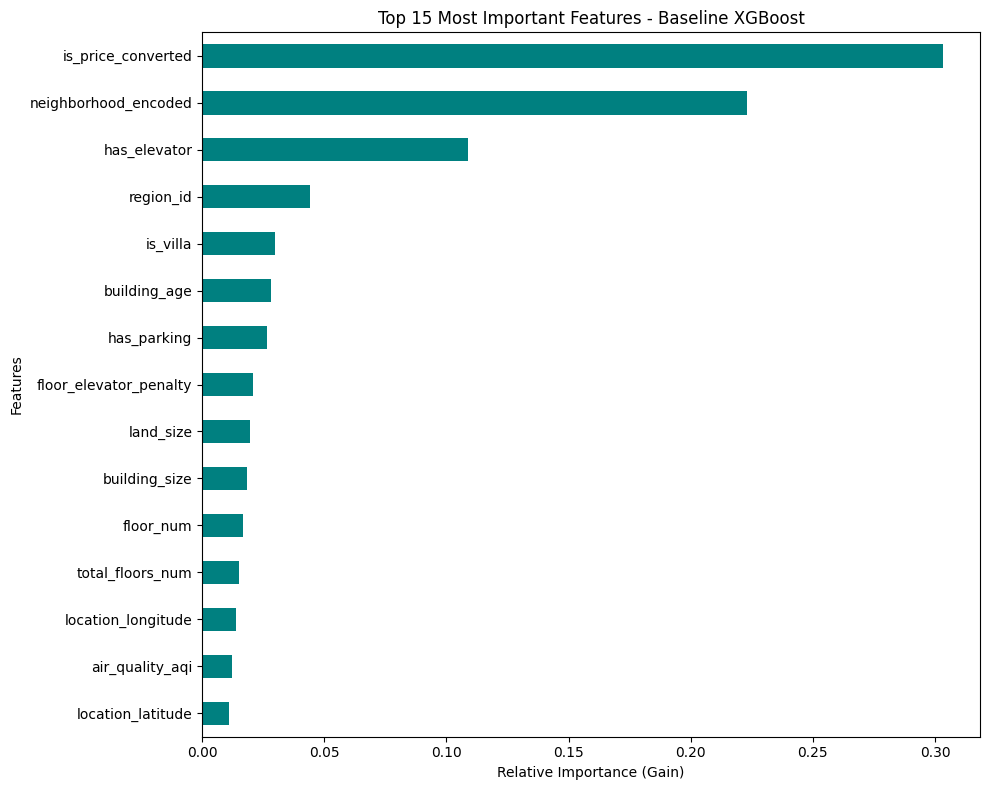

In [ ]:
# ==========================================
# Phase 3 - Cell 1: Download Data, Train Baseline XGBoost & Feature Selection
# ==========================================
import pandas as pd
import xgboost as xgb
from sklearn.metrics import mean_absolute_error, r2_score
import matplotlib.pyplot as plt
from google.cloud import bigquery

PROJECT_ID = 'siavak-temp-aliz'
DATASET_ID = 'divar_ml_data_prepration'
client = bigquery.Client(project=PROJECT_ID)

print("⏳ ۱. در حال دانلود داده‌های آموزش و آزمایش از BigQuery...")
# دانلود داده‌هایی که در فاز قبلی تمیز و Encode کردیم
query_train = f"SELECT * FROM `{PROJECT_ID}.{DATASET_ID}.ml_micro_train_encoded`"
query_test = f"SELECT * FROM `{PROJECT_ID}.{DATASET_ID}.ml_micro_test_encoded`"

df_train = client.query(query_train).to_dataframe()
df_test = client.query(query_test).to_dataframe()

print(f"✅ داده‌ها دانلود شدند! ابعاد Train: {df_train.shape}")

# جداسازی X و y
X_train = df_train.drop(columns=['target_ratio'])
y_train = df_train['target_ratio']

X_test = df_test.drop(columns=['target_ratio'])
y_test = df_test['target_ratio']

print("⏳ ۲. در حال آموزش مدل XGBoost (Baseline)...")
# مدل یکپارچه (شامل فروش، رهن و اجاره) با تنظیمات پایه
model = xgb.XGBRegressor(
    objective='reg:squarederror',
    n_estimators=400,
    learning_rate=0.05,
    max_depth=7,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    n_jobs=-1
)

model.fit(X_train, y_train)
print("✅ آموزش به پایان رسید!")

# ارزیابی
y_pred = model.predict(X_test)
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print("-" * 50)
print(f"🎯 ارزیابی مدل پایه (Baseline Evaluation):")
print(f"📌 خطای MAE (میانگین انحراف ضریب): {mae:.4f}")
print(f"📌 ضریب R-Squared: {r2:.4f}")
print("-" * 50)

# استخراج اهمیت ویژگی‌ها
importances = pd.Series(model.feature_importances_, index=X_train.columns).sort_values(ascending=False)

# چاپ ۵ متغیری که کمترین تاثیر را داشته‌اند (برای تصمیم‌گیری در مورد حذف)
print("\n🗑️ ۵ متغیری که کمترین تاثیر را در مدل داشتند (کاندیدای حذف):")
print(importances.tail(5))

# رسم نمودار ۱۵ ویژگی برتر
plt.figure(figsize=(10, 8))
importances.head(15).sort_values().plot(kind='barh', color='teal')
plt.title('Top 15 Most Important Features - Baseline XGBoost')
plt.xlabel('Relative Importance (Gain)')
plt.ylabel('Features')
plt.tight_layout()
plt.show()

In [ ]:
# ==========================================
# Phase 3 - Cell 2: Hyperparameter Tuning with Optuna
# ==========================================
!pip install optuna -q

import optuna
import xgboost as xgb
from sklearn.metrics import mean_absolute_error, r2_score
import pandas as pd
import matplotlib.pyplot as plt

print("🤖 ربات Optuna روشن شد! در حال جستجوی بهترین تنظیمات...")
print("⏳ این مرحله ممکن است ۵ الی ۱۰ دقیقه طول بکشد. لطفا صبور باشید.\n")

# ۱. تعریف تابع هدف (Objective Function) برای Optuna
def objective(trial):
    # فضایی که Optuna اجازه دارد در آن جستجو کند
    param = {
        'objective': 'reg:squarederror',
        'n_estimators': trial.suggest_int('n_estimators', 200, 600, step=50),
        'max_depth': trial.suggest_int('max_depth', 5, 10),
        'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.1, log=True),
        'subsample': trial.suggest_float('subsample', 0.6, 1.0, step=0.1),
        'colsample_bytree': trial.suggest_float('colsample_bytree', 0.6, 1.0, step=0.1),
        'random_state': 42,
        'n_jobs': -1
    }

    # ساخت و آموزش مدل موقت
    model_cv = xgb.XGBRegressor(**param)
    model_cv.fit(X_train, y_train)

    # پیش‌بینی و محاسبه خطا
    preds = model_cv.predict(X_test)
    mae = mean_absolute_error(y_test, preds)

    # ما می‌خواهیم MAE کمترین مقدار ممکن شود
    return mae

# ۲. ساخت یک Study و شروع جستجو (اجرای ۲۰ تست هوشمند)
optuna.logging.set_verbosity(optuna.logging.WARNING) # برای جلوگیری از شلوغ شدن خروجی
study = optuna.create_study(direction='minimize')
study.optimize(objective, n_trials=20, show_progress_bar=True)

# ۳. استخراج بهترین تنظیمات پیدا شده
best_params = study.best_params
print("-" * 50)
print("🏆 بهترین تنظیماتی که Optuna پیدا کرد:")
for key, value in best_params.items():
    print(f"   * {key}: {value}")
print("-" * 50)

# ۴. آموزش مدل نهایی (Tuned Model) با بهترین تنظیمات
print("\n⏳ در حال آموزش مدل نهایی با تنظیمات کشف شده...")
best_params['objective'] = 'reg:squarederror'
best_params['random_state'] = 42
best_params['n_jobs'] = -1

tuned_model = xgb.XGBRegressor(**best_params)
tuned_model.fit(X_train, y_train)
print("✅ آموزش مدل طلایی به پایان رسید!\n")

# ۵. ارزیابی مدل نهایی
y_pred_tuned = tuned_model.predict(X_test)
mae_tuned = mean_absolute_error(y_test, y_pred_tuned)
r2_tuned = r2_score(y_test, y_pred_tuned)

print("-" * 50)
print("🎯 نتایج ارزیابی مدل بهینه‌شده (Tuned Model Evaluation):")
print(f"📌 میانگین قدر مطلق خطا (MAE): {mae_tuned:.4f}")
print(f"📌 ضریب تعیین (R-Squared): {r2_tuned:.4f}")
print("-" * 50)

# (اختیاری) ذخیره مدل برای استفاده در ابزار نهایی
# tuned_model.save_model("divar_micro_xgboost_tuned.json")
# print("💾 مدل طلایی با نام divar_micro_xgboost_tuned.json ذخیره شد.")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 425.6/425.6 kB 9.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 264.7/264.7 kB 22.1 MB/s eta 0:00:00
🤖 ربات Optuna روشن شد! در حال جستجوی بهترین تنظیمات...
⏳ این مرحله ممکن است ۵ الی ۱۰ دقیقه طول بکشد. لطفا صبور باشید.



  0%|          | 0/20 [00:00<?, ?it/s]

--------------------------------------------------
🏆 بهترین تنظیماتی که Optuna پیدا کرد:
   * n_estimators: 400
   * max_depth: 10
   * learning_rate: 0.04921451716177124
   * subsample: 0.9
   * colsample_bytree: 0.7
--------------------------------------------------

⏳ در حال آموزش مدل نهایی با تنظیمات کشف شده...


In [ ]:
# ==========================================
# Data Leakage Audit Cell
# ==========================================
print("🔍 در حال بازرسی امنیتی داده‌های آموزش (Data Leakage Audit)...")

# ۱. بررسی ستون‌های مشکوک به قیمت
suspicious_keywords = ['price', 'rent', 'credit', 'sqm', 'target']
leaked_columns = [col for col in X_train.columns if any(kw in col.lower() for kw in suspicious_keywords)]

if leaked_columns:
    print(f"🚨 هشدار خطرناک: ستون‌های قیمتی زیر در X_train جا مانده‌اند: {leaked_columns}")
else:
    print("✅ هیچ ستون مستقیمی از قیمت در داده‌های آموزش یافت نشد.")

# ۲. بررسی نشت زمان (در صورت وجود ستون تاریخ)
# اگر ستون تاریخ را در X_train نگه داشته بودید، می‌توانستیم هم‌پوشانی زمانی را چک کنیم.
# از آنجا که ستون‌های تاریخ را حذف کرده‌اید، مدل زمان را نمی‌بیند،
# اما تقسیم تصادفی همچنان الگوهای کلانِ آینده را به مدل تزریق کرده است.

print("-" * 50)
print("📊 لیست کامل ویژگی‌های ورودی به مدل برای بررسی چشمی:")
print(X_train.columns.tolist())

In [ ]:
import json
from google.colab import files



# 2. Export Micro Model (Tuned)
tuned_model.save_model("micro_model.json")
files.download("micro_model.json")

# 3. Export Neighborhood Target Encoding Dictionary
# محاسبه مجدد میانگین‌ها برای ساخت دیکشنری
means = y_train.groupby(df.iloc[:split_index]['neighborhood_slug']).mean()
global_mean = y_train.mean()

encoding_dict = means.to_dict()
encoding_dict['GLOBAL_MEAN'] = global_mean

with open("neighborhood_encoding.json", "w") as f:
    json.dump(encoding_dict, f)
files.download("neighborhood_encoding.json")